# **Data Cleaning Report**

Cleaning of the *Mall Customer Segmentation* dataset: profiling, outliers, missing values, duplicates, and data types.

> **Data:** reads `data/Mall_Customers.csv` (included in this repository; see `data/README.md`). This notebook writes the cleaned file to `data/processed/mall_customers_clean.csv`, which is used by modules 4-6.

**Note on file formats:** CSV opens in many applications but does not preserve data types, whereas Parquet is more efficient and keeps the original types (e.g., `object` / `category`). This notebook saves the cleaned data as CSV.

## **1. Initial Data Profiling**

The first step is to profile the data to understand the basic characteristics of the dataset. This covers loading the data and checking its structure, data types, and basic statistics.

### **1.1 Load Required Libraries**

Import all Python libraries used in the analysis and cleaning process. The main ones are `pandas` and `numpy` for data manipulation, and `matplotlib` and `seaborn` for visualization.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **1.2 Load the Dataset**

The dataset is 'Mall Customer Segmentation Data'. It is loaded from `data/Mall_Customers.csv` into a pandas DataFrame named `df`. Column names are standardized to one English `snake_case` schema, because the raw column names differ slightly between Kaggle uploads.

In [2]:
DATA_PATH = Path('../data/Mall_Customers.csv')
OUTPUT_PATH = Path('../data/processed/mall_customers_clean.csv')

df = pd.read_csv(DATA_PATH)

# Standardize column names and gender labels
df = df.rename(columns={
    'CustomerID': 'customer_id', 'Customer ID': 'customer_id',
    'Gender': 'gender', 'Genre': 'gender',
    'Age': 'age',
    'Annual Income (k$)': 'annual_income_k_usd',
    'Spending Score (1-100)': 'spending_score',
})
df['gender'] = df['gender'].replace({'Pria': 'Male', 'Wanita': 'Female'})

print(f"Dataset loaded from '{DATA_PATH}'")

Dataset loaded from '../data/Mall_Customers.csv'


### **1.3 Basic Information Check**

After loading, we check the structure of the data: the first five rows, the total number of rows and columns, and the DataFrame summary with data types and non-null counts per column.

In [3]:
# Show the first 5 rows
print("First five rows:")
display(df.head())

# Show the number of rows and columns
print(f"\nNumber of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

# Show general DataFrame information, including data types
print("\nDataFrame info (data types, null values, etc.):")
df.info()

First five rows:


,customer_id,gender,age,annual_income_k_usd,spending_score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Number of rows: 200
Number of columns: 5

DataFrame info (data types, null values, etc.):
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   customer_id          200 non-null    int64
 1   gender               200 non-null    str  
 2   age                  200 non-null    int64
 3   annual_income_k_usd  200 non-null    int64
 4   spending_score       200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


### **1.4 Descriptive Statistics**

Descriptive statistics give an overview of the distribution of both categorical and numerical data, helping us understand the central tendency, spread, and range of each attribute.

In [4]:
print("\n--- Gender Column Analysis ---")

# Count each gender category
gender_counts = df['gender'].value_counts()
print("Distribution by gender:")
print(gender_counts)


--- Gender Column Analysis ---
Distribution by gender:
gender
Female    112
Male       88
Name: count, dtype: int64


**Gender column result:**<br>
Of the 200 customers, 112 are female and 88 are male, so there are slightly more female customers in this dataset.

In [5]:
print("\nDescriptive statistics for numerical columns:")

# .T transposes the output to make it easier to read
display(df.describe().T)


Descriptive statistics for numerical columns:


,count,mean,std,min,25%,50%,75%,max
customer_id,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
annual_income_k_usd,200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
spending_score,200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


**Descriptive statistics for numerical columns:**<br>
- **Age**: Customer ages range from 18 to 70, with a mean of about 38.85 years.
- **Annual income**: Annual income ranges from \$15,000 to \$137,000, with a mean of \$60,560.
- **Spending score**: Spending scores (1-100) range from 1 to 99, with a mean and median that are nearly equal (about 50), indicating a fairly symmetric distribution.

## **2. Data Cleaning Process**

In this stage we identify and handle data problems such as *outliers*, *missing values*, duplicate rows, and data type errors.

### **2.1 Handling Outliers**

#### **a. Identifying Outliers**

Outliers are values far outside the normal range of the data. They are identified in two ways: visually with a **box plot**, and statistically with the **Interquartile Range (IQR)** method.

**Identification with box plots**

Box plots show the spread of the data and reveal outliers visually in each numerical column.

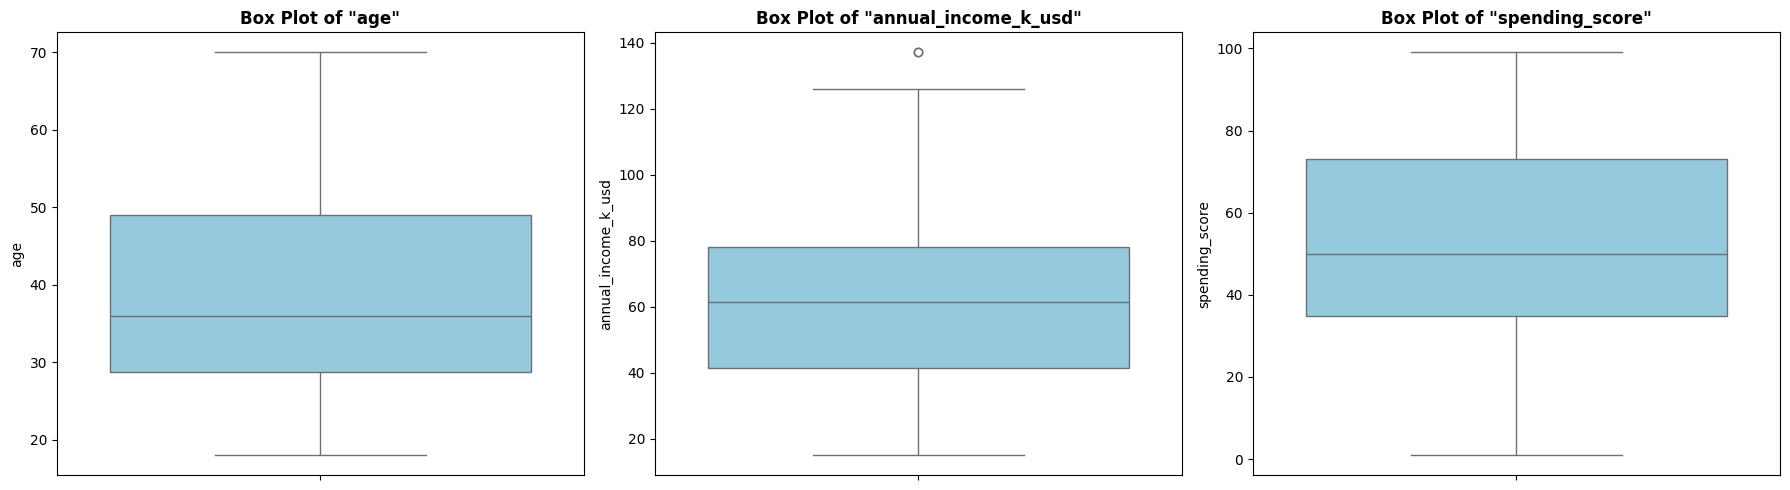

In [6]:
numerical_cols = ['age', 'annual_income_k_usd', 'spending_score']

plt.figure(figsize=(18, 5))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Box Plot of "{col}"', fontweight='bold')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

The box plots show that `age` and `spending_score` have no significant outliers. In `annual_income_k_usd`, however, a data point lies above the upper whisker, indicating a potential outlier.

**Identification with IQR analysis**

To confirm the outliers statistically, we apply the IQR method to the `annual_income_k_usd` column.

In [7]:
col_to_handle = 'annual_income_k_usd'

# Q1 and Q3 of the income column (expected: 41.50 and 78.00)
Q1 = df[col_to_handle].quantile(0.25)
Q3 = df[col_to_handle].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print(f"--- IQR Outlier Analysis for Column: {col_to_handle} ---")
print(f"Q1 (1st quartile): {Q1}")
print(f"Q3 (3rd quartile): {Q3}")
print(f"IQR (Interquartile Range): {IQR}")
print(f"Upper bound (for outlier detection): {upper_bound:.2f}")

# Identify and display the outlier rows
outliers = df[df[col_to_handle] > upper_bound]
print(f"\nFound {len(outliers)} outliers:")
display(outliers)

--- IQR Outlier Analysis for Column: annual_income_k_usd ---
Q1 (1st quartile): 41.5
Q3 (3rd quartile): 78.0
IQR (Interquartile Range): 36.5
Upper bound (for outlier detection): 132.75

Found 2 outliers:


,customer_id,gender,age,annual_income_k_usd,spending_score
198,199,Male,32,137,18
199,200,Male,30,137,83


The IQR method detects 2 outlier rows in `annual_income_k_usd`: customers whose annual income is above the upper bound (132.75).

#### **b. Justification and Action**

Outliers in income can affect statistical results such as the mean and can distort machine learning models. Instead of deleting these valuable rows, we use **capping**.

This method replaces outlier values with the upper bound that is still considered reasonable (here, 132.75). The goal is to reduce the extreme influence of outliers without losing the rows.

In [8]:
# Work on a copy so the original data stays unchanged
df_cleaned = df.copy()

# Cap the outliers
df_cleaned[col_to_handle] = np.where(
    df_cleaned[col_to_handle] > upper_bound,
    upper_bound,                     # replace outliers with the upper bound
    df_cleaned[col_to_handle]        # keep the original value otherwise
)

print("\nDescriptive statistics AFTER handling outliers:")
display(df_cleaned.describe().T)


Descriptive statistics AFTER handling outliers:


,count,mean,std,min,25%,50%,75%,max
customer_id,200.0,100.5000,57.879185,1.0,50.75,100.5,150.25,200.00
age,200.0,38.8500,13.969007,18.0,28.75,36.0,49.00,70.00
annual_income_k_usd,200.0,60.5175,26.143551,15.0,41.50,61.5,78.00,132.75
spending_score,200.0,50.2000,25.823522,1.0,34.75,50.0,73.00,99.00


**Before / after comparison**

To confirm that capping worked, we compare the box plots before and after handling the outliers.


Comparison before and after capping:


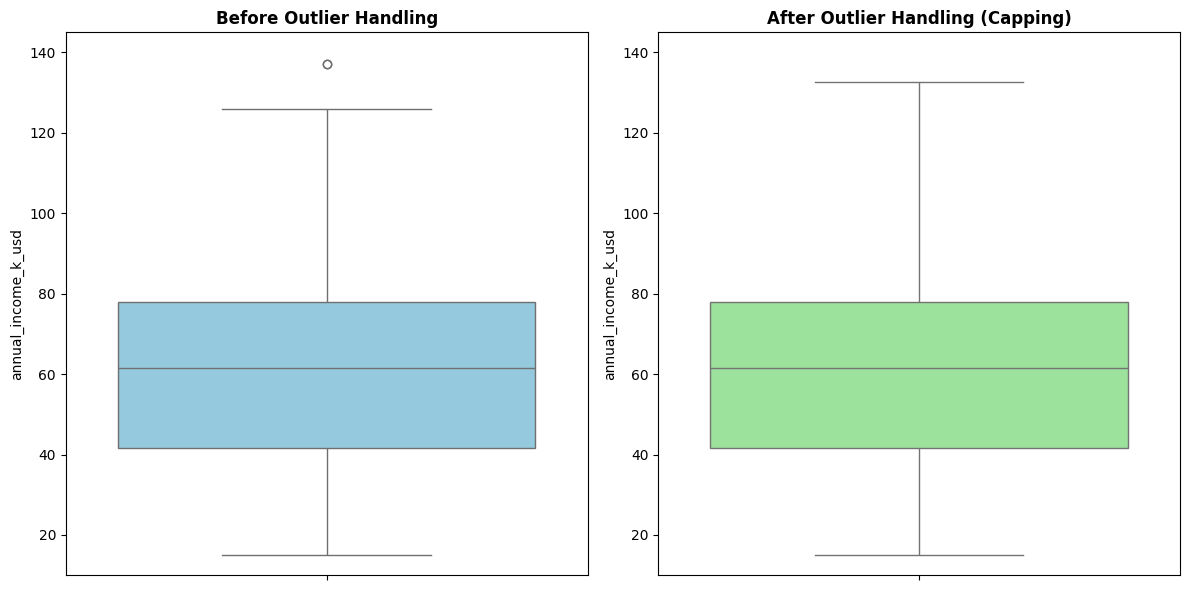

In [9]:
print("\nComparison before and after capping:")
plt.figure(figsize=(12, 6))

# Box plot before
plt.subplot(1, 2, 1)
sns.boxplot(y=df[col_to_handle], color='skyblue')
plt.title('Before Outlier Handling', fontweight='bold')
plt.ylim(10, 145)  # same y-axis scale

# Box plot after
plt.subplot(1, 2, 2)
sns.boxplot(y=df_cleaned[col_to_handle], color='lightgreen')
plt.title('After Outlier Handling (Capping)', fontweight='bold')
plt.ylim(10, 145)  # same y-axis scale

plt.tight_layout()
plt.show()

### **2.2 Handling Missing Values**

#### **Identifying Missing Values**

We check whether any values are missing or empty in each column.

In [10]:
df_cleaned.isnull().sum()

customer_id            0
gender                 0
age                    0
annual_income_k_usd    0
spending_score         0
dtype: int64

**Result:** No missing values were found in any column of this dataset, so no action is needed at this stage.

### **2.3 Handling Duplicates**

#### **Identifying Duplicates**

Checking for duplicates ensures every row is unique. We check on `customer_id`, which should uniquely identify each customer.

In [11]:
df_cleaned.duplicated(subset=["customer_id"]).sum()

np.int64(0)

**Result:** There are no duplicate values in `customer_id`, meaning every row already represents a unique customer.

### **2.4 Handling Data Types**

#### **a. Identifying Data Types**

Making sure each column has an appropriate data type is important for storage efficiency and analysis accuracy.

In [12]:
print(df_cleaned.dtypes)

customer_id              int64
gender                     str
age                      int64
annual_income_k_usd    float64
spending_score           int64
dtype: object


**Result:** The `gender` column is stored as a string column (`object`; displayed as `str` in pandas 3). That is not wrong, but converting it to `category` is more memory-efficient and semantically better for a column with few unique values (Male, Female). In addition, `annual_income_k_usd` became `float64` after the outlier values were changed, so it needs to be converted back to `int64`.

#### **b. Justification and Action**

`gender` is converted to `category` for memory optimization and semantic consistency, and `annual_income_k_usd` is converted back to `int64`. The other numerical columns are already `int64`, so they need no change.

In [13]:
df_cleaned["customer_id"] = df_cleaned["customer_id"].astype(int)
df_cleaned["gender"] = df_cleaned["gender"].astype("category")
df_cleaned["annual_income_k_usd"] = df_cleaned["annual_income_k_usd"].astype(int)
df_cleaned["spending_score"] = df_cleaned["spending_score"].astype(int)

print(df_cleaned.dtypes)

customer_id               int64
gender                 category
age                       int64
annual_income_k_usd       int64
spending_score            int64
dtype: object


## **3. Save the Cleaned Dataset**

The cleaned data is written to `data/processed/` for use in the next modules.

In [14]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df_cleaned.to_csv(OUTPUT_PATH, index=False)
print(f"Saved cleaned dataset to {OUTPUT_PATH}")

Saved cleaned dataset to ../data/processed/mall_customers_clean.csv


## **4. Conclusion**

Data cleaning of the *Mall Customer* dataset is complete. Of the four main areas checked, two problems needed handling, while the other two were already in good condition.

Summary of the actions taken:
1. **Outliers**: 2 outliers were found in `annual_income_k_usd`. They were handled with **capping**, replacing the outlier values with a reasonable upper bound (132.75) to reduce distortion in the analysis without losing data.
2. **Data types**: The `gender` column was changed from `object` to `category` for memory optimization and semantic fit. `annual_income_k_usd` was converted back to `int64` for consistency with the other values.
3. **Missing values**: No missing values were found in the dataset.
4. **Duplicates**: No duplicate rows were found based on `customer_id`.

After this process the dataset is cleaner, more consistent, and more reliable, and is ready for the next stages of analysis, such as customer segmentation or predictive modeling.